# Life Expectancy (WHO) Dataset Description
| Feature | Description |
|----------|-------------|
| **Country** | Name of the country. |
| **Year** | The year for that record (e.g., 2000–2015). |
| **Status** | The development status of the country (“Developed” or “Developing”). |
| **Life expectancy** | The average number of years a person live |
| **Adult Mortality** | Number of deaths per 1000 population of people aged between 15 and 60. |
| **Infant deaths** | Number of infant deaths per 1000 population. |
| **Alcohol** | Recorded per capita (15+) consumption (in litres of pure alcohol) per year. |
| **Percentage expenditure** | Health expenditure as a percentage of GDP. |
| **Hepatitis B** | Percentage of 1-year-old children immunized against Hepatitis B (HepB3). |
| **Measles** | Percentage of 1-year-old children immunized against measles. |
| **BMI** | Average Body Mass Index (BMI) of the adult population in the country. |
| **Under-five deaths** | Number of deaths of children under 5 years old in the given year per country. |
| **Polio** | Percentage of 1-year-old children who received all three doses of polio vaccine (Pol3). |
| **Total expenditure** | General government health expenditure as a percentage of total government expenditure. |
| **Diphtheria** | Percentage of 1-year-old children immunized with DTP3 (diphtheria, tetanus, pertussis). |
| **HIV/AIDS** | Deaths per 1,000 live births caused by HIV/AIDS among children aged 0–4 years. |
| **GDP** | Gross Domestic Product per capita (in US dollars). |
| **Population** | Total population of the country in that year. |
| **Thinness 1–19 years** | Prelavence of thinness among children and adolescents in percentage |
| **Thinness 5–9 years** | Prelavence of thinness among children in percentage |
| **Income composition of resources** | Income index (0–1) |
| **Schooling** | Average number of years of schooling for adults (mean years of schooling). |

---

**Source:** [Life Expectancy (WHO) Dataset on Kaggle](https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who)  
**Creator:** Kumar Asharshi  
**Period Covered:** 2000–2015  
**Rows:** 2,938  
**Columns:** 22  


# **1 - Load the Life Expectancy Dataset**

In [ ]:
# import the required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [ ]:
# Load the dataset
life_expectancy_v1 = pd.read_csv('../data/raw/Life_Expectancy_Data.csv')
life_expectancy_v1.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [ ]:
# Strip whitespace from column names
life_expectancy_v1.columns = life_expectancy_v1.columns.str.strip()

# rename `thinness 1–19 years` feature to `thinness 10–19 years`
life_expectancy_v1 = life_expectancy_v1.rename(columns={'thinness  1-19 years': 'thinness 10–19 years'})

# **2 - Data Exploration**

In [ ]:
life_expectancy_v1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [ ]:
life_expectancy_v1.describe()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 10–19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.000000,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,2904.000000,2938.000000,2919.000000,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000
mean,2007.518720,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,38.321247,42.035739,82.550188,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793
std,4.613841,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,20.044034,160.445548,23.428046,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.000000,0.000000,3.000000,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000
25%,2004.000000,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,19.300000,0.000000,78.000000,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000
50%,2008.000000,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,43.500000,4.000000,93.000000,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000
75%,2012.000000,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,56.200000,28.000000,97.000000,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,99.000000,17.60000,99.000000,50.600000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000


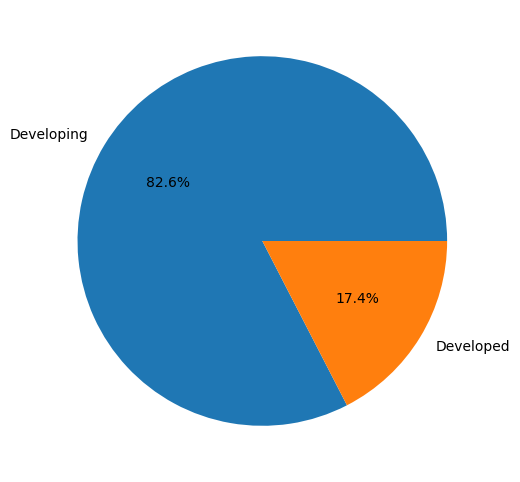

In [ ]:
# Plot a pie chart of the `Status` feature
plt.figure(figsize=(6, 6))

labels = life_expectancy_v1['Status'].value_counts().index
sizes = life_expectancy_v1['Status'].value_counts().values
plt.pie(sizes, labels=labels, autopct='%1.1f%%')

plt.show()

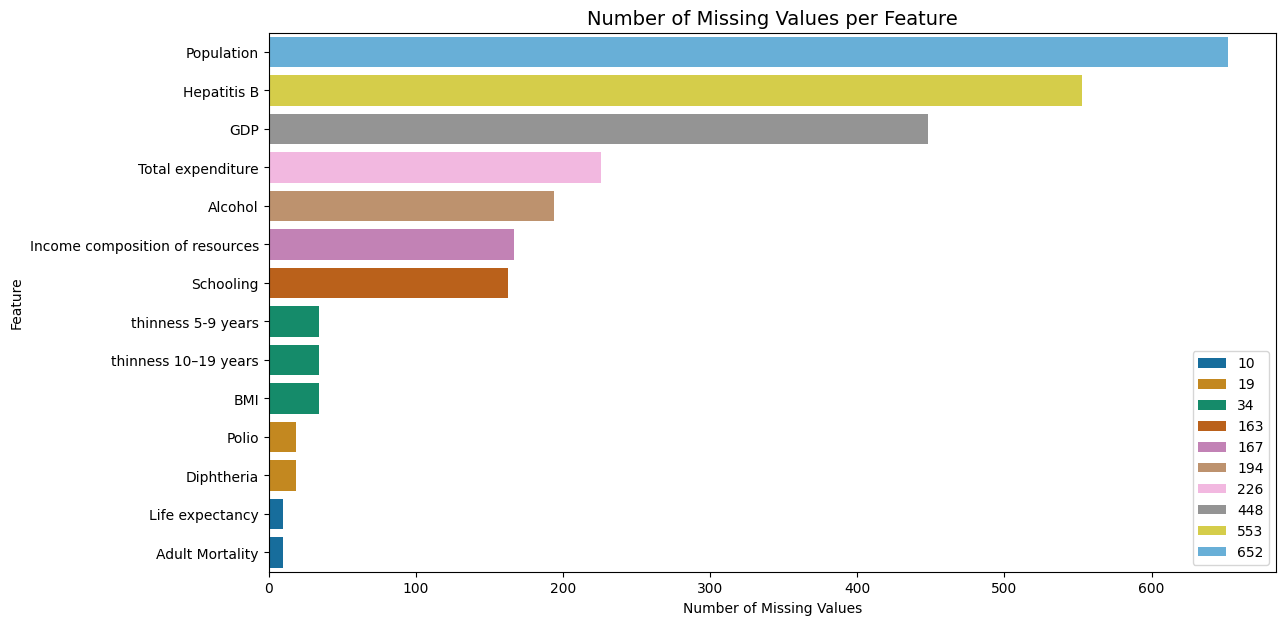

In [ ]:
def plot_missing_values(df, figsize=(13, 7), palette='colorblind'):
    """
    Plots a barplot showing the number of missing values per feature in a DataFrame.
    """
    # Count missing values per column
    missing_counts = df.isna().sum()

    # Keep only columns with missing values
    missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

    # If no missing values, inform the user
    if missing_counts.empty:
        return

    # Plot
    plt.figure(figsize=figsize)
    sns.barplot(
        y=missing_counts.index,
        x=missing_counts.values,
        hue=missing_counts.values,
        palette=palette
    )
    plt.title('Number of Missing Values per Feature', fontsize=14)
    plt.xlabel('Number of Missing Values')
    plt.ylabel('Feature')
    plt.show()


plot_missing_values(life_expectancy_v1)

# **3 - Data Cleaning and Validation**

## **3.a Drop `infant deaths`, `percentage expenditure`, `Measles`, `under-five deaths`, `Population`, `GDP` Features**

In [ ]:
columns_to_drop = ['infant deaths', 'percentage expenditure', 'Measles', 'under-five deaths', 'Population', 'GDP']
life_expectancy_v1 = life_expectancy_v1.drop(columns=columns_to_drop)

## **3.b Replace outliers by NaNs**

In [ ]:
columns_to_replace_their_outliers_by_NaNs = ['Adult Mortality', 'BMI']

# Work on a copy
life_expectancy_v2 = life_expectancy_v1.copy()

for col in columns_to_replace_their_outliers_by_NaNs:

    # Calculate global lower and upper bounds (5th and 95th percentiles)
    lower_bound = life_expectancy_v2[col].quantile(0.1)
    upper_bound = life_expectancy_v2[col].quantile(0.9)

    # Detect outliers
    is_outlier = (life_expectancy_v2[col] < lower_bound) | (life_expectancy_v2[col] > upper_bound)

    # Replace outliers with NaN
    life_expectancy_v2[col] = np.where(is_outlier, np.nan, life_expectancy_v2[col])

    # Update original dataframe
    life_expectancy_v1[col] = life_expectancy_v2[col]

# Clean up
del life_expectancy_v2

In [ ]:
# Make the entries of Schooling feature who has 0s as NaN
life_expectancy_v1["Schooling"] = np.where (
                                      life_expectancy_v1["Schooling"] == 0,
                                      np.nan,
                                      life_expectancy_v1["Schooling"]
                                  )

## **3.c Import GDP and Population datasets and combine them into the original dataset.**

In [ ]:
gdp_v1 = pd.read_csv('../data/external/GDP_measured_in_millions.csv')
gdp_v1.head()

,Unnamed: 0,Country,Year,GDP
0,0,Afghanistan,2000,3521.0
1,1,Angola,2000,12646.0
2,2,Albania,2000,3488.0
3,3,United Arab Emirates,2000,102987.0
4,4,Argentina,2000,317759.0


In [ ]:
gdp_v1.drop(columns=['Unnamed: 0'], inplace=True)
gdp_v1.head()

,Country,Year,GDP
0,Afghanistan,2000,3521.0
1,Angola,2000,12646.0
2,Albania,2000,3488.0
3,United Arab Emirates,2000,102987.0
4,Argentina,2000,317759.0


In [ ]:
gdp_v1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2992 entries, 0 to 2991
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Country  2992 non-null   object 
 1   Year     2992 non-null   int64  
 2   GDP      2966 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 70.3+ KB


In [ ]:
population_v1 = pd.read_csv('../data/external/population_data.csv')
population_v1.head()

,Country,Year,Population
0,Afghanistan,2000,20130327
1,Afghanistan,2001,20284307
2,Afghanistan,2002,21378117
3,Afghanistan,2003,22733049
4,Afghanistan,2004,23560654


In [ ]:
population_v1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2656 entries, 0 to 2655
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Country     2656 non-null   object
 1   Year        2656 non-null   int64 
 2   Population  2656 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 62.4+ KB


In [ ]:
# Combine Life_expectancy dataset with the gdp dataset
life_expectancy_v1 = pd.merge(life_expectancy_v1, gdp_v1, on=['Country', 'Year'], how='left')
life_expectancy_v1.head()

,Country,Year,Status,Life expectancy,Adult Mortality,Alcohol,Hepatitis B,BMI,Polio,Total expenditure,Diphtheria,HIV/AIDS,thinness 10–19 years,thinness 5-9 years,Income composition of resources,Schooling,GDP
0,Afghanistan,2015,Developing,65.0,263.0,0.01,65.0,NaN,6.0,8.16,65.0,0.1,17.2,17.3,0.479,10.1,20057.0
1,Afghanistan,2014,Developing,59.9,271.0,0.01,62.0,18.6,58.0,8.18,62.0,0.1,17.5,17.5,0.476,10.0,20616.0
2,Afghanistan,2013,Developing,59.9,268.0,0.01,64.0,18.1,62.0,8.13,64.0,0.1,17.7,17.7,0.470,9.9,20170.0
3,Afghanistan,2012,Developing,59.5,272.0,0.01,67.0,17.6,67.0,8.52,67.0,0.1,17.9,18.0,0.463,9.8,20293.0
4,Afghanistan,2011,Developing,59.2,275.0,0.01,68.0,17.2,68.0,7.87,68.0,0.1,18.2,18.2,0.454,9.5,17890.0


In [ ]:
life_expectancy_v1 = life_expectancy_v1.rename(columns={'GDP': 'GDP_in_millions'})

In [ ]:
# Combine the population and life_expectancy dataset
life_expectancy_v1 = pd.merge(life_expectancy_v1, population_v1, on=['Country', 'Year'], how='left')
life_expectancy_v1.head()

,Country,Year,Status,Life expectancy,Adult Mortality,Alcohol,Hepatitis B,BMI,Polio,Total expenditure,Diphtheria,HIV/AIDS,thinness 10–19 years,thinness 5-9 years,Income composition of resources,Schooling,GDP_in_millions,Population
0,Afghanistan,2015,Developing,65.0,263.0,0.01,65.0,NaN,6.0,8.16,65.0,0.1,17.2,17.3,0.479,10.1,20057.0,33831764.0
1,Afghanistan,2014,Developing,59.9,271.0,0.01,62.0,18.6,58.0,8.18,62.0,0.1,17.5,17.5,0.476,10.0,20616.0,32792523.0
2,Afghanistan,2013,Developing,59.9,268.0,0.01,64.0,18.1,62.0,8.13,64.0,0.1,17.7,17.7,0.470,9.9,20170.0,31622704.0
3,Afghanistan,2012,Developing,59.5,272.0,0.01,67.0,17.6,67.0,8.52,67.0,0.1,17.9,18.0,0.463,9.8,20293.0,30560034.0
4,Afghanistan,2011,Developing,59.2,275.0,0.01,68.0,17.2,68.0,7.87,68.0,0.1,18.2,18.2,0.454,9.5,17890.0,29347708.0


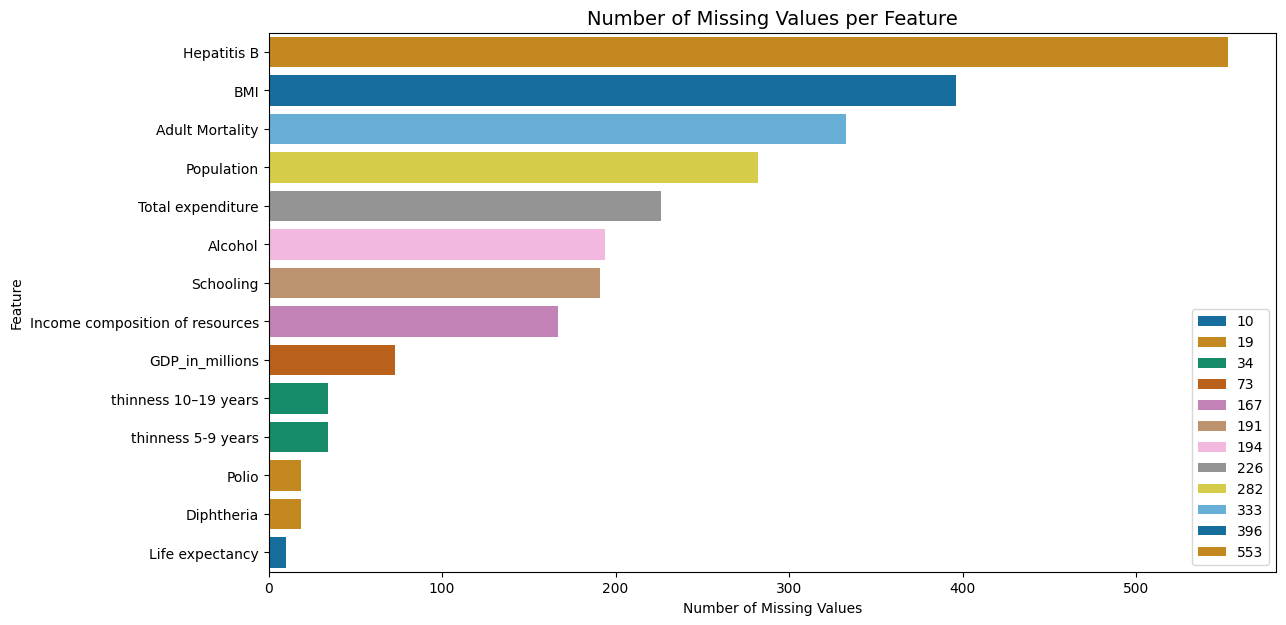

In [ ]:
plot_missing_values(life_expectancy_v1)

## **3.d Sub-Impute features who has at most 6 missing values and Remove the remaing rows that have at least one missing value**

In [ ]:
# Operate on a copy of the dataset
life_expectancy_v2 = life_expectancy_v1.copy()

for col in life_expectancy_v2.columns:
    if col not in ["Country", "Status"]:
      # filter only those has at most 6 missing values
      life_expectancy_v2[col+'_isna'] = life_expectancy_v2[col].isna()
      count = life_expectancy_v2.groupby('Country')[col+'_isna'].sum()
      count = count[ count <= 6 ]
      countries_to_keep = count.index.tolist()
      life_expectancy_v2 = life_expectancy_v2[life_expectancy_v2["Country"].isin(countries_to_keep)]

      medians = life_expectancy_v2.groupby('Country')[col].median()
      life_expectancy_v1[col] = life_expectancy_v1[col].fillna(life_expectancy_v1['Country'].map(medians))


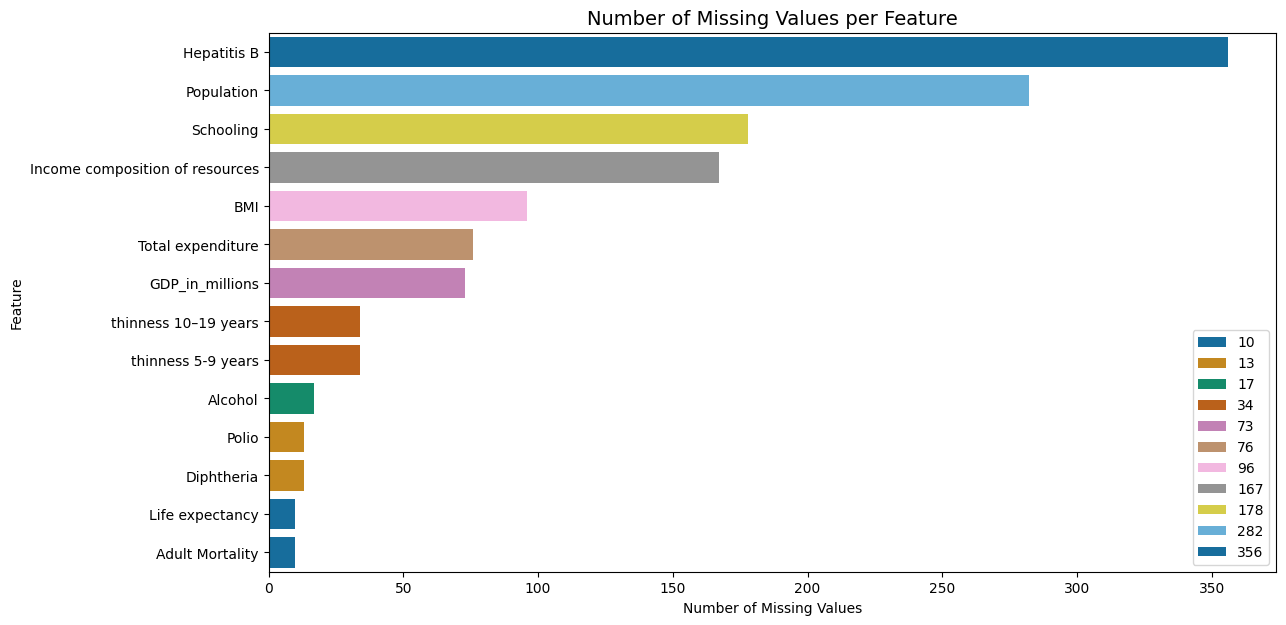

In [ ]:
plot_missing_values(life_expectancy_v1)

In [ ]:
life_expectancy_v1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 18 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   Alcohol                          2921 non-null   float64
 6   Hepatitis B                      2582 non-null   float64
 7   BMI                              2842 non-null   float64
 8   Polio                            2925 non-null   float64
 9   Total expenditure                2862 non-null   float64
 10  Diphtheria                       2925 non-null   float64
 11  HIV/AIDS                         2938 non-null   float64
 12  thinness 10–19 years

In [ ]:
# Remove rows who has at least one missing feature
life_expectancy_v1 = life_expectancy_v1[~life_expectancy_v1.isna().any(axis=1)].reset_index(drop=True)
life_expectancy_v1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2140 entries, 0 to 2139
Data columns (total 18 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2140 non-null   object 
 1   Year                             2140 non-null   int64  
 2   Status                           2140 non-null   object 
 3   Life expectancy                  2140 non-null   float64
 4   Adult Mortality                  2140 non-null   float64
 5   Alcohol                          2140 non-null   float64
 6   Hepatitis B                      2140 non-null   float64
 7   BMI                              2140 non-null   float64
 8   Polio                            2140 non-null   float64
 9   Total expenditure                2140 non-null   float64
 10  Diphtheria                       2140 non-null   float64
 11  HIV/AIDS                         2140 non-null   float64
 12  thinness 10–19 years

In [ ]:
life_expectancy_v1['GDP_per_capita'] = (life_expectancy_v1['GDP_in_millions']*1000000) / life_expectancy_v1['Population']
life_expectancy_v1 = life_expectancy_v1.drop(columns=['GDP_in_millions', 'Population'])

## **3.e - Data Validation**

In [ ]:
# Validate that Year column values are between 2000 and 2015
assert life_expectancy_v1['Year'].between(2000, 2015).all()

# Validate Status feature contains only two values "Developing" and "Developed"
assert life_expectancy_v1['Status'].isin(['Developing', 'Developed']).all()

# Validate Life Expectancy column values
assert life_expectancy_v1['Life expectancy'].between(0, 122).all()

# Validate Adult Mortality column values are between 0 and 1000
assert life_expectancy_v1['Adult Mortality'].between(0, 1000).all()

# Validate Alcohol column values are non-negative
assert (life_expectancy_v1['Alcohol'] > 0).all()

# Validate Hepatitis B feature values that they are between 0 and 100
assert life_expectancy_v1['Hepatitis B'].between(0, 100).all()

# Validate Total expenditure feature values that they are between 0 and 100
assert life_expectancy_v1['Total expenditure'].between(0, 100).all()

# Validate Diphtheria feature values that they are between 0 and 100
assert life_expectancy_v1['Diphtheria'].between(0, 100).all()

# Validate HIV/AIDS column values are between 0 and 1000
assert life_expectancy_v1['HIV/AIDS'].between(0, 1000).all()

# Validate `thinness 5-9 years` and `thinness 10-19 years` features values that they are between 0 and 100
assert life_expectancy_v1['thinness 10–19 years'].between(0, 100).all()
assert life_expectancy_v1['thinness 5-9 years'].between(0, 100).all()

# Validate `Income composition of resources` feature values that they are between 0 and 1
assert life_expectancy_v1['Income composition of resources'].between(0, 1).all()

# Validate `Schooling` column values are non-negative
assert (life_expectancy_v1['Schooling'] > 0).all()

# Validate `GDP_in_millions` column values are non-negative
assert (life_expectancy_v1['GDP_per_capita'] > 0).all()

In [ ]:
life_expectancy_v1.set_index(['Country', 'Year'], inplace=True)

# **4-Feature Engineering**

In [ ]:
life_expectancy_v1['thinness 5-19 years'] = (life_expectancy_v1['thinness 5-9 years'] + life_expectancy_v1['thinness 10–19 years']) / 2
life_expectancy_v1 = life_expectancy_v1.drop(columns=['thinness 5-9 years', 'thinness 10–19 years'])

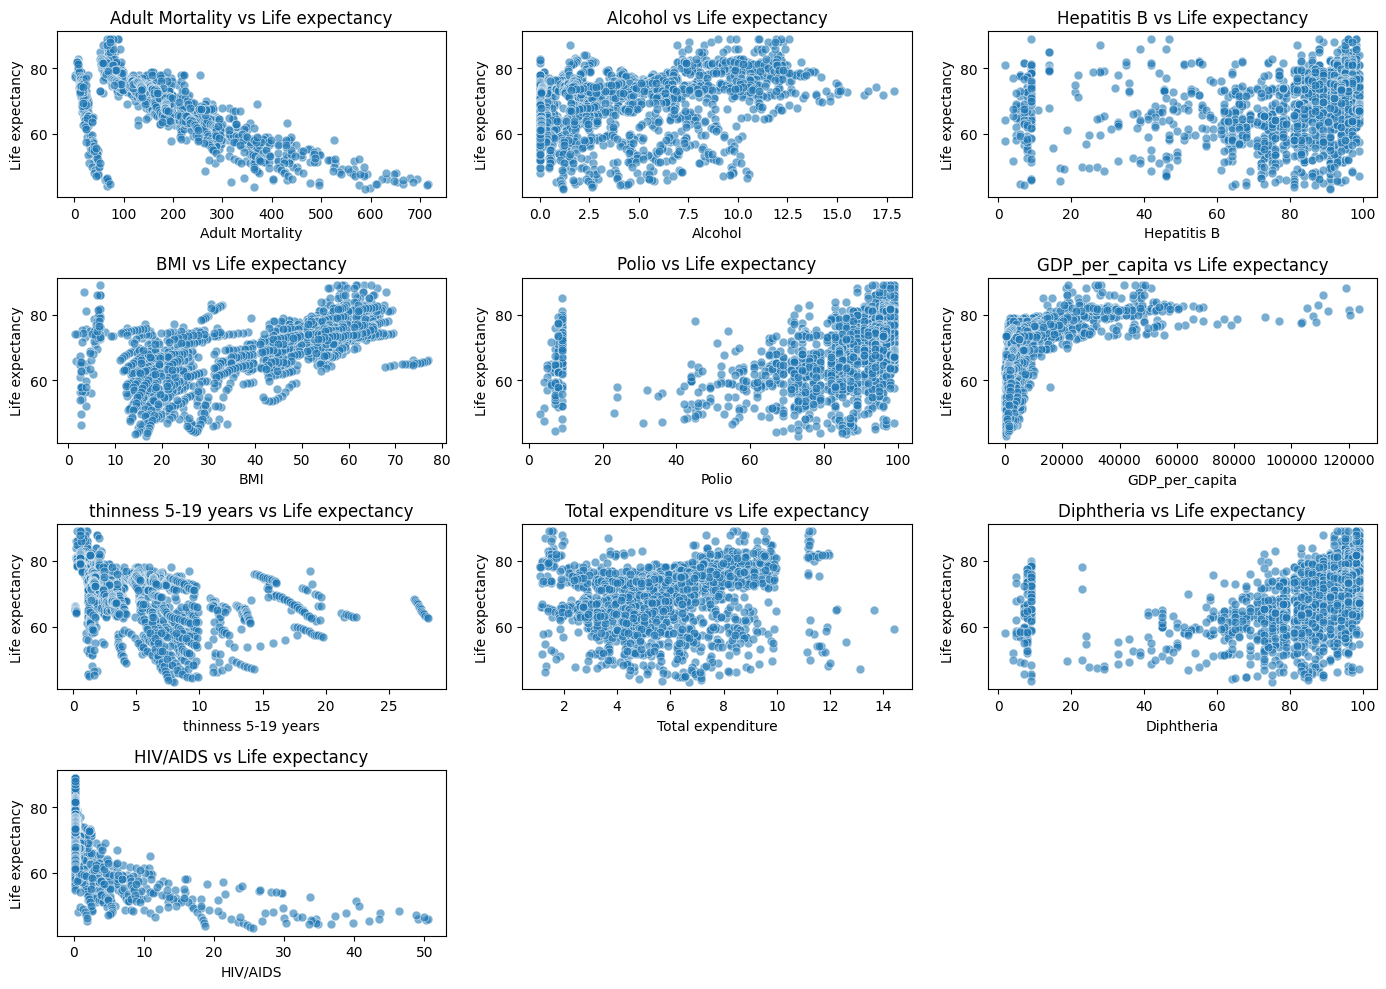

In [ ]:
df = life_expectancy_v1

# Target feature
target = 'Life expectancy'

# Fill in the features you want to plot
features = [
    'Adult Mortality',
    'Alcohol',
    'Hepatitis B',
    'BMI',
    'Polio',
    'GDP_per_capita',
    'thinness 5-19 years',
    'Total expenditure',
    'Diphtheria',
    'HIV/AIDS'
]

# Plot each feature against the target
plt.figure(figsize=(14, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(4, 3, i)
    sns.scatterplot(data=df, x=feature, y=target, alpha=0.6, s=40)
    plt.title(f"{feature} vs {target}")
    plt.xlabel(feature)
    plt.ylabel(target)

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Life Expectancy')

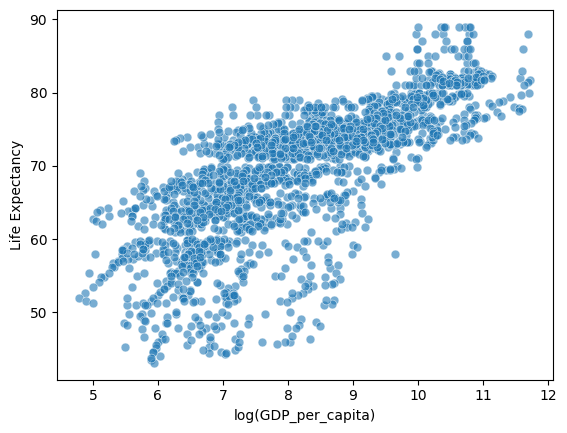

In [ ]:
sns.scatterplot(x=np.log1p(life_expectancy_v1['GDP_per_capita']), y=life_expectancy_v1['Life expectancy'], alpha=0.6, s=40)
plt.xlabel("log(GDP_per_capita)")
plt.ylabel("Life Expectancy")

Text(0, 0.5, 'Life Expectancy')

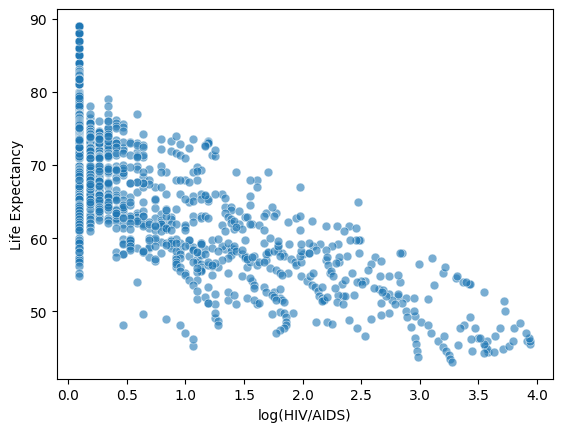

In [ ]:
sns.scatterplot(x=np.log1p(life_expectancy_v1['HIV/AIDS']), y=life_expectancy_v1['Life expectancy'], alpha=0.6, s=40)
plt.xlabel("log(HIV/AIDS)")
plt.ylabel("Life Expectancy")

## **4.a Encoding `Status` categorical Feature**

In [ ]:
categorical_features = ['Status']

## **4.d Transform percentage to values between 0 and 1, the same for features measured per 1000 population**

In [ ]:
def custom_transformer1(df):
  df = df.copy()
  features_to_divide_by_1000 = ['Adult Mortality', 'HIV/AIDS']
  features_to_divide_by_100 = ['Polio', 'Diphtheria', 'thinness 5-19 years']



  for col in df.columns:
    if col in features_to_divide_by_1000:
      df[col] = df[col] / 1000
    elif col in features_to_divide_by_100:
      df[col] = df[col] / 100
  return df

## **4.d Standardize all numrical features using StandardScaler**

In [ ]:
numerical_features_to_be_standardized = [
    'Adult Mortality',
    'BMI',
    'Income composition of resources',
    'HIV/AIDS'
]


## **4.e Detect and Remove collinearity between non-target features**

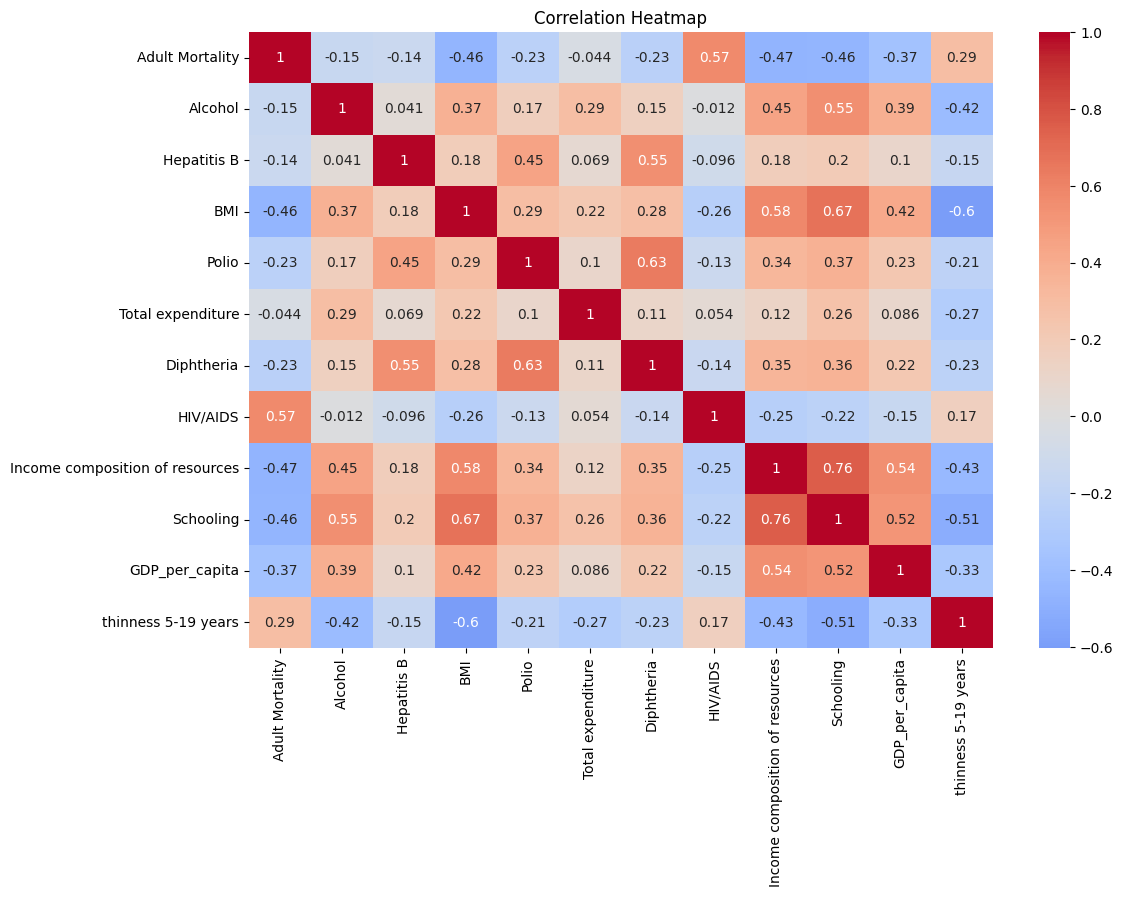

In [ ]:
corr_matrix = life_expectancy_v1.drop(columns=['Life expectancy', 'Status']).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
corr = life_expectancy_v1.drop(columns=['Status']).corr()['Life expectancy']
print(corr)

Life expectancy                    1.000000
Adult Mortality                   -0.739211
Alcohol                            0.346932
Hepatitis B                        0.212279
BMI                                0.640129
Polio                              0.375042
Total expenditure                  0.158971
Diphtheria                         0.382660
HIV/AIDS                          -0.590128
Income composition of resources    0.719604
Schooling                          0.742230
GDP_per_capita                     0.543678
thinness 5-19 years               -0.457184
Name: Life expectancy, dtype: float64


In [ ]:
def custom_transformer2(df):
  df = df.copy()
  # Drop `Schooling`, `Total expenditure`, `Hepatits B`, `Alcohol`, `Polio`, `thinness 5-19 years` features
  df = df.drop(columns=['Schooling', 'Total expenditure', 'Hepatitis B', 'Alcohol', 'Polio', 'thinness 5-19 years', 'Diphtheria'])
  return df

# **5- Model Training and testing**

In [ ]:
preprocessor = Pipeline([
    ('custom_t1', FunctionTransformer(custom_transformer1)),
    ('custom_t2', FunctionTransformer(custom_transformer2)),
    ('column_transforms', ColumnTransformer(
        transformers=[
            ('log_gdp', FunctionTransformer(np.log1p), ['GDP_per_capita']),
            ('log_HIV/AIDS', FunctionTransformer(np.log1p), ['HIV/AIDS']),
            ('num_scale', StandardScaler(), numerical_features_to_be_standardized),
            ('cat_encode', OneHotEncoder(handle_unknown='ignore'), categorical_features)
        ]
    ))
])

linear_regression_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression(fit_intercept=True))
])

random_forest_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor())
])

In [ ]:
X = life_expectancy_v1.drop(columns=['Life expectancy'])
y = life_expectancy_v1['Life expectancy']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=life_expectancy_v1['Status']
)

In [ ]:
linear_regression_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('custom_t1',
                                  FunctionTransformer(func=<function custom_transformer1 at 0x7b8eac758c20>)),
                                 ('custom_t2',
                                  FunctionTransformer(func=<function custom_transformer2 at 0x7b8eac3ee0c0>)),
                                 ('column_transforms',
                                  ColumnTransformer(transformers=[('log_gdp',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>),
                                                                   ['GDP_per_capita']),
                                                                  ('log_HIV/AIDS',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>),
                                                                   ['HIV/AIDS']),
                                                                  ('num_scale',
                                                                   StandardScaler(),
                                                                   ['Adult '
                                                                    'Mortality',
                                                                    'BMI',
                                                                    'Income '
                                                                    'composition '
                                                                    'of '
                                                                    'resources',
                                                                    'HIV/AIDS']),
                                                                  ('cat_encode',
                                                                   OneHotEncoder(handle_unknown='ignore'),
                                                                   ['Status'])]))])),
                ('regressor', LinearRegression())])

In [ ]:
y_pred = linear_regression_model.predict(X_train)

rmse = np.sqrt(mean_squared_error(y_train, y_pred))
mae = mean_absolute_error(y_train, y_pred)

print(f"Linear Regression: RMSE was {rmse:.4f} and MAE was {mae:.4f}")

Linear Regression: RMSE was 3.4741 and MAE was 2.5996


In [ ]:
y_pred = linear_regression_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"Linear Regression: RMSE was {rmse:.4f} and MAE was {mae:.4f}")

Linear Regression: RMSE was 3.5543 and MAE was 2.7208


In [ ]:
random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('custom_t1',
                                  FunctionTransformer(func=<function custom_transformer1 at 0x7b8eac758c20>)),
                                 ('custom_t2',
                                  FunctionTransformer(func=<function custom_transformer2 at 0x7b8eac3ee0c0>)),
                                 ('column_transforms',
                                  ColumnTransformer(transformers=[('log_gdp',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>),
                                                                   ['GDP_per_capita']),
                                                                  ('log_HIV/AIDS',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>),
                                                                   ['HIV/AIDS']),
                                                                  ('num_scale',
                                                                   StandardScaler(),
                                                                   ['Adult '
                                                                    'Mortality',
                                                                    'BMI',
                                                                    'Income '
                                                                    'composition '
                                                                    'of '
                                                                    'resources',
                                                                    'HIV/AIDS']),
                                                                  ('cat_encode',
                                                                   OneHotEncoder(handle_unknown='ignore'),
                                                                   ['Status'])]))])),
                ('regressor', RandomForestRegressor())])

In [ ]:
y_pred = random_forest_model.predict(X_train)

rmse = np.sqrt(mean_squared_error(y_train, y_pred))
mae = mean_absolute_error(y_train, y_pred)

print(f"Random Rorest Regressor: RMSE was {rmse:.4f} and MAE was {mae:.4f}")

Random Rorest Regressor: RMSE was 0.7432 and MAE was 0.4830


In [ ]:
y_pred = random_forest_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"Random Rorest Regressor: RMSE was {rmse:.4f} and MAE was {mae:.4f}")

Random Rorest Regressor: RMSE was 1.8187 and MAE was 1.2007
